# CODE TO LOOK AT SNPS with varied AF per population
Author: Gracie Gordon 2025

In [1]:
import genetics_plotting_utils as gu
import pandas as pd
import gwaslab as gl
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt

by .GlobalEnv when processing object ‘.pbd_env’


In [2]:
def make_scatterplot_viz(qtl_df,title='AF',xlim='None'):
    Ancestry_palette = {"EUR_AF": "#a6cee3", "AFR_AF":  "#1f78b4", "EAS_AF": "#b2df8a", "AMR_AF": "#33a02c"}
    test=qtl_df[['variant_id','ref','alt','phenotype_id','gene_id','AFR_AF','AMR_AF','EAS_AF','EUR_AF','pval_nominal','pval_nominal_threshold']]
    # filter to only include significant SNPs
    test=test[test['pval_nominal']<test['pval_nominal_threshold']]

    df=pd.melt(test, id_vars=['variant_id','ref','alt','phenotype_id','gene_id','EUR_AF'], value_vars=['AFR_AF','AMR_AF','EAS_AF'], var_name='pop', value_name='maf')
    
    ## simplify by flipping the AF if the AF is >0.5 in EUR (so it's truly the MAF)
    for index, row in df.iterrows():
        if row['EUR_AF'] > 0.5:
            df.at[index, 'EUR_AF'] = 1 - row['EUR_AF']
            df.at[index, 'maf'] = 1 - row['maf']
    if(xlim=='None'):
        sns.scatterplot(data=df, x='EUR_AF', 
                    y='maf', 
                    hue='pop',
                    palette=Ancestry_palette,
                    alpha=0.8,s=5).set_title(title)
        plt.ylabel('AF')
        plt.xlabel('EUR MAF')
        # Add an abline (y = x)
        # Add a vertical line at x = 0.5
        plt.axvline(x=0.1, color='red', linestyle='--', linewidth=1)
        #plt.axvline(x=0.9, color='red', linestyle='--', linewidth=1)
        # Add a horizontal line at y = 0.5
        plt.axhline(y=0.1, color='red', linestyle='--', linewidth=1)
        #plt.axhline(y=0.9, color='red', linestyle='--', linewidth=1)
        plt.legend(
                #title="eqtl_snp",
                bbox_to_anchor=(1.05, 1),  # Position the legend outside the plot
                loc='upper left'           # Align the legend to the upper left of the anchor
            )
        plt.show()
    else:
        sns.scatterplot(data=df, x='EUR_AF', 
                    y='maf', 
                    hue='pop',
                    palette=Ancestry_palette,
                    alpha=0.8,s=5).set_title(title)
        plt.ylabel('AF')
        plt.xlabel('EUR MAF')
        # Add an abline (y = x)
        # Add a vertical line at x = 0.5
        #plt.axvline(x=0.1, color='red', linestyle='--', linewidth=1)
        #plt.axvline(x=0.9, color='red', linestyle='--', linewidth=1)
        # Add a horizontal line at y = 0.5
        plt.axhline(y=0.1, color='red', linestyle='--', linewidth=1)
        #plt.axhline(y=0.9, color='red', linestyle='--', linewidth=1)
        plt.legend(
                #title="eqtl_snp",
                bbox_to_anchor=(1.05, 1),  # Position the legend outside the plot
                loc='upper left'           # Align the legend to the upper left of the anchor
            )
        plt.xlim(0, xlim)
        plt.show()


# Read data

In [3]:
#read in rna data for one chr
rna_test=pd.read_csv("/gstore/data/ctgbioinfo/gordom14/ICC/data/QTL_calling/rna/L1_manual/B/B.cis_qtl_snp.22.annot.txt", sep="\t")
rna_egenes=pd.read_csv('/gstore/data/ctgbioinfo/gordom14/ICC/data/QTL_calling/rna/L1_manual/B/B.cis_qtl_egene.22.txt', sep="\t")
rna_test=rna_test.merge(rna_egenes[['phenotype_id','pval_nominal_threshold']], how='left', on='phenotype_id')

In [ ]:
#read in rna data for one chr
atac_test=pd.read_csv("/gstore/data/ctgbioinfo/gordom14/ICC/data/QTL_calling/atac/permissive/L1_manual/B/B.cis_qtl_snp.22.annot.txt", sep="\t")
atac_egenes=pd.read_csv('/gstore/data/ctgbioinfo/gordom14/ICC/data/QTL_calling/atac/permissive/L1_manual/B/B.cis_qtl_egene.22.txt', sep="\t")
atac_test=atac_test.merge(atac_egenes[['phenotype_id','pval_nominal_threshold']], how='left', on='phenotype_id')

In [ ]:
#filter to just significant snps for atac
atac_test=atac_test[atac_test['pval_nominal'] < atac_test['pval_nominal_threshold']]

In [ ]:
# annotate significant snps in rna
rna_test['eqtl_snp']='No'
#rna_test[rna_test['pval_nominal'] < rna_test['pval_nominal_threshold']]['eqtl_snp']='Yes'



#atac_test[ (atac_test['pos']>atac_test['peak_start']) & (atac_test['pos']<atac_test['peak_end'])]['in_peak']='Yes'
# Identify the rows that satisfy the condition
condition = ( rna_test['pval_nominal'] < rna_test['pval_nominal_threshold'] )

# Use .iloc to assign 'Yes' to the 'in_peak' column for the matching rows
rna_test.loc[condition, 'eqtl_snp'] = 'Yes'

## make plots

In [4]:
# try adding histograms
Ancestry_palette = {"EUR_AF": "#a6cee3", "AFR_AF":  "#1f78b4", "EAS_AF": "#b2df8a", "AMR_AF": "#33a02c"}
test=rna_test[['variant_id','ref','alt','phenotype_id','gene_id','AFR_AF','AMR_AF','EAS_AF','EUR_AF','pval_nominal','pval_nominal_threshold']]
# filter to only include significant SNPs
test=test[test['pval_nominal']<test['pval_nominal_threshold']]

df=pd.melt(test, id_vars=['variant_id','ref','alt','phenotype_id','gene_id','EUR_AF'], value_vars=['AFR_AF','AMR_AF','EAS_AF'], var_name='pop', value_name='maf')
for index, row in df.iterrows():
    if row['EUR_AF'] > 0.5:
        df.at[index, 'EUR_AF'] = 1 - row['EUR_AF']
        df.at[index, 'maf'] = 1 - row['maf']

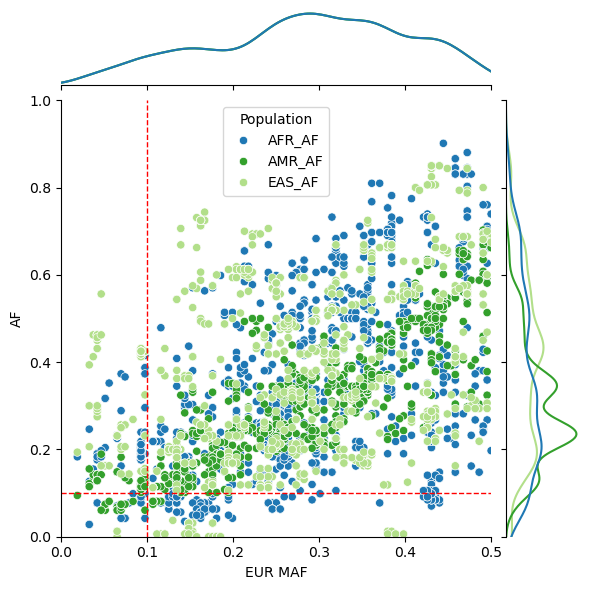

In [12]:
# Create a JointGrid for scatter plot with marginal histograms
g = sns.JointGrid(data=df, x='EUR_AF', y='maf', hue='pop', palette=Ancestry_palette)

# Add scatter plot to the center
g.plot_joint(sns.scatterplot)
# Add histograms to the margins
#g.plot_marginals(sns.histplot, bins=30, alpha=0.6, kde=True)
g.plot_marginals(sns.kdeplot)

# Add legend
g.ax_joint.legend(title='Population')
g.ax_joint.set_xlim(0, 0.5)
g.ax_joint.set_ylim(0, 1)
g.ax_joint.axhline(y=0.1, color='red', linestyle='--', linewidth=1)
g.ax_joint.axvline(x=0.1, color='red', linestyle='--', linewidth=1)

g.ax_joint.set_ylabel('AF')
g.ax_joint.set_xlabel('EUR MAF')
# Show the plot
plt.show()

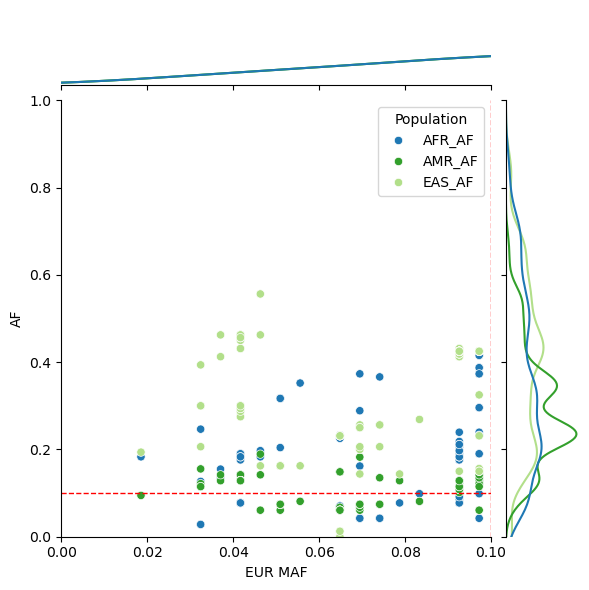

In [11]:
# Create a JointGrid for scatter plot with marginal histograms
g = sns.JointGrid(data=df, x='EUR_AF', y='maf', hue='pop', palette=Ancestry_palette)

# Add scatter plot to the center
g.plot_joint(sns.scatterplot)
# Add histograms to the margins
#g.plot_marginals(sns.histplot, bins=30, alpha=0.6, kde=True)
g.plot_marginals(sns.kdeplot)

# Add legend
g.ax_joint.legend(title='Population')
g.ax_joint.set_xlim(0, 0.1)
g.ax_joint.set_ylim(0, 1)
g.ax_joint.axhline(y=0.1, color='red', linestyle='--', linewidth=1)
g.ax_joint.axvline(x=0.1, color='red', linestyle='--', linewidth=1)

g.ax_joint.set_ylabel('AF')
g.ax_joint.set_xlabel('EUR MAF')
# Show the plot
plt.show()